In [ ]:
!pip install -q kagglehub pgmpy pandas numpy scikit-learn matplotlib networkx ucimlrepo

In [ ]:
# 3. Write a program to construct a Bayesian network considering medical data.
# Use this model to demonstrate the diagnosis of heart patients using the standard Heart Disease Data Set
# (You can use Java/Python ML library classes/API.)

In [ ]:
# Practical 3: Bayesian Network for Heart Disease Diagnosis

# Step 1: Import required libraries
import os
import glob
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination

In [ ]:
# Step 2: Download and load Heart Disease dataset

from ucimlrepo import fetch_ucirepo

print("Downloading Heart Disease dataset...")

heart_disease = fetch_ucirepo(id=45)

# Get features and target
X = heart_disease.data.features
y = heart_disease.data.targets

# Combine features and target
df = pd.concat([X, y], axis=1)

print("\nDataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst five records:")
print(df.head())

# Clean column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("-", "_", regex=False)
)


Dataset shape: (303, 14)

Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

First five records:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   1       145   233    1        2      150      0      2.3      3   
1   67    1   4       160   286    0        2      108      1      1.5      2   
2   67    1   4       120   229    0        2      129      1      2.6      2   
3   37    1   3       130   250    0        0      187      0      3.5      3   
4   41    0   2       130   204    0        2      172      0      1.4      1   

    ca  thal  num  
0  0.0   6.0    0  
1  3.0   3.0    2  
2  2.0   7.0    1  
3  0.0   3.0    0  
4  0.0   3.0    0  


In [ ]:
# Step 3: Data Cleaning
df = df.replace(["?", "NA", "N/A", ""], np.nan)

for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Find target column
target_candidates = [
    "condition", "num", "target",
    "heartdisease", "heart_disease",
    "diagnosis", "output"
]

target_col = next(
    (c for c in target_candidates if c in df.columns),
    None
)

if target_col is None:
    target_col = df.columns[-1]

# Remove rows with missing target
df = df.dropna(subset=[target_col]).copy()

# Convert target into binary classes
# 0 = No Disease, 1 = Disease
df["disease"] = (df[target_col] > 0).astype(int)

df = df.drop(columns=[target_col])

# Remove empty columns
df = df.dropna(axis=1, how="all")

# Fill missing values with median
for col in df.columns:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)

print("\nDisease distribution:")
print(df["disease"].value_counts())


Disease distribution:
disease
0    164
1    139
Name: count, dtype: int64


In [ ]:
# Step 4: Discretize continuous attributes
continuous_features = [
    "age", "trestbps", "chol",
    "thalach", "oldpeak"
]

for col in continuous_features:
    if col in df.columns:
        df[col] = pd.cut(
            df[col],
            bins=3,
            labels=False,
            duplicates="drop"
        )

# Convert all attributes into integers
for col in df.columns:
    df[col] = df[col].astype(int)

# Separate input and target
X = df.drop(columns=["disease"])
y = df["disease"]

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Prepare training data
train_data = X_train.copy()
train_data["disease"] = y_train

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 242
Testing samples: 61


In [ ]:
# Step 5: Build and Train Bayesian Network

# Create network edges
edges = [
    ("disease", feature)
    for feature in X.columns
]

model = DiscreteBayesianNetwork(edges)
# print(model.edges())

# Estimate probability distributions
cpds = []

for node in model.nodes():

    estimator = BayesianEstimator(model, train_data)

    cpd = estimator.estimate_cpd(
        node,
        prior_type="BDeu",
        equivalent_sample_size=5
    )

    cpds.append(cpd)

# Add probability distributions to model
model.add_cpds(*cpds)

print("\nNetwork Structure Valid:", model.check_model())

[('disease', 'age'), ('disease', 'sex'), ('disease', 'cp'), ('disease', 'trestbps'), ('disease', 'chol'), ('disease', 'fbs'), ('disease', 'restecg'), ('disease', 'thalach'), ('disease', 'exang'), ('disease', 'oldpeak'), ('disease', 'slope'), ('disease', 'ca'), ('disease', 'thal')]


/tmp/ipykernel_902/667843855.py:17: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(model, train_data)
/tmp/ipykernel_902/667843855.py:17: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(model, train_data)
/tmp/ipykernel_902/667843855.py:17: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(model, train_data)
/tmp/ipykernel_902/667843855.py:17: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = Bayes


Network Structure Valid: True


/tmp/ipykernel_902/667843855.py:17: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(model, train_data)
/tmp/ipykernel_902/667843855.py:17: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(model, train_data)
/tmp/ipykernel_902/667843855.py:17: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(model, train_data)
/tmp/ipykernel_902/667843855.py:17: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = Bayes

In [ ]:
# Step 6: Prediction using Bayesian Inference
inference = VariableElimination(model)

predictions = []
probabilities_disease = []

for _, row in X_test.iterrows():

    evidence = {
        feature: int(row[feature])
        for feature in X.columns
    }

    result = inference.query(
        variables=["disease"],
        evidence=evidence,
        show_progress=False
    )

    state_names = list(result.state_names["disease"])
    probability_values = result.values

    probability_map = dict(
        zip(state_names, probability_values)
    )

    p0 = float(probability_map.get(0, 0.0))
    p1 = float(probability_map.get(1, 0.0))

    predicted = int(p1 >= p0)

    predictions.append(predicted)
    probabilities_disease.append(p1)



BAYESIAN NETWORK EVALUATION
Accuracy: 91.80%

Classification Report:
              precision    recall  f1-score   support

  No Disease       1.00      0.85      0.92        33
     Disease       0.85      1.00      0.92        28

    accuracy                           0.92        61
   macro avg       0.92      0.92      0.92        61
weighted avg       0.93      0.92      0.92        61

Confusion Matrix:
[[28  5]
 [ 0 28]]


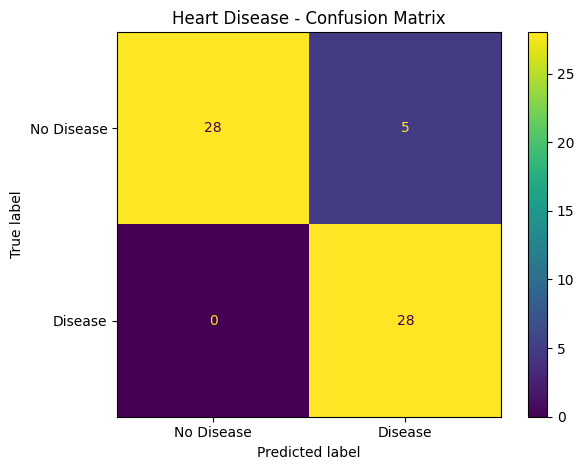

In [ ]:
# Step 7: Model Evaluation
y_pred = np.array(predictions)
y_actual = y_test.to_numpy()

accuracy = accuracy_score(y_actual, y_pred)

print("\n" + "=" * 45)
print("BAYESIAN NETWORK EVALUATION")
print("=" * 45)

print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_actual,
        y_pred,
        labels=[0, 1],
        target_names=["No Disease", "Disease"],
        zero_division=0
    )
)

# Plot confusion matrix
cm = confusion_matrix(y_actual, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Disease", "Disease"]
).plot()

plt.title("Heart Disease - Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# Step 8: Test one patient
patient = X_test.iloc[0]

evidence = {
    feature: int(patient[feature])
    for feature in X.columns
}

result = inference.query(
    variables=["disease"],
    evidence=evidence,
    show_progress=False
)

states = list(result.state_names["disease"])
probability_map = dict(zip(states, result.values))

p0 = float(probability_map.get(0, 0.0))
p1 = float(probability_map.get(1, 0.0))

print("\n" + "=" * 45)
print("SAMPLE PATIENT PREDICTION")
print("=" * 45)

print("\nPatient attributes:")
print(patient)

print(f"\nP(No Disease | Evidence): {p0 * 100:.2f}%")
print(f"P(Disease | Evidence): {p1 * 100:.2f}%")

print("\nPredicted result:")

print(
    "Heart Disease Present"
    if p1 >= p0
    else "No Heart Disease"
)

actual = int(y_test.iloc[0])

print(
    "\nActual result:",
    "Heart Disease Present" if actual == 1
    else "No Heart Disease"
)

print("\nProgram completed successfully.")


SAMPLE PATIENT PREDICTION

Patient attributes:
age         1
sex         1
cp          4
trestbps    1
chol        0
fbs         0
restecg     2
thalach     2
exang       0
oldpeak     0
slope       1
ca          0
thal        3
Name: 219, dtype: int64

P(No Disease | Evidence): 93.94%
P(Disease | Evidence): 6.06%

Predicted result:
No Heart Disease

Actual result: No Heart Disease

Program completed successfully.
